In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from uri_template import expand

df = pd.read_csv('customers-10000.csv')
display(df.head())

,Index,Customer Id,First Name,Last Name,Company,City,Country,Phone 1,Phone 2,Email,Subscription Date,Website
0,1,EB54EF1154C3A78,Heather,Callahan,Mosley-David,Lake Jeffborough,Norway,043-797-5229,915.112.1727,urangel@espinoza-francis.net,2020-08-26,http://www.escobar.org/
1,2,10dAcafEBbA5FcA,Kristina,Ferrell,"Horn, Shepard and Watson",Aaronville,Andorra,932-062-1802,(209)172-7124x3651,xreese@hall-donovan.com,2020-04-27,https://tyler-pugh.info/
2,3,67DAB15Ebe4BE4a,Briana,Andersen,Irwin-Oneal,East Jordan,Nepal,8352752061,(567)135-1918,haleybraun@blevins-sexton.com,2022-03-22,https://www.mack-bell.net/
3,4,6d350C5E5eDB4EE,Patty,Ponce,Richardson Group,East Kristintown,Northern Mariana Islands,302.398.3833,196-189-7767x770,hohailey@anthony.com,2020-07-02,https://delacruz-freeman.org/
4,5,5820deAdCF23EFe,Kathleen,Mccormick,Carson-Burch,Andresmouth,Macao,001-184-153-9683x1497,552.051.2979x342,alvaradojesse@rangel-shields.com,2021-01-17,https://welch.info/


In [2]:
contagem_paises = df["Country"].value_counts()

pais_campeao = contagem_paises.index[0]

qtd_assinaturas = contagem_paises.iloc[0]

print(f"O país campeão é {pais_campeao} com {qtd_assinaturas} assinaturas ativas!"
)

contagem_cidades = df["City"].value_counts()

cidade = contagem_cidades.index[0]

qtd_assinaturas = contagem_cidades.iloc[0]

print(f"A maior cidade com {qtd_assinaturas} assinaturas ativas é  {cidade} !")

O país campeão é Korea com 84 assinaturas ativas!
A maior cidade com 4 assinaturas ativas é  Port Marilyn !


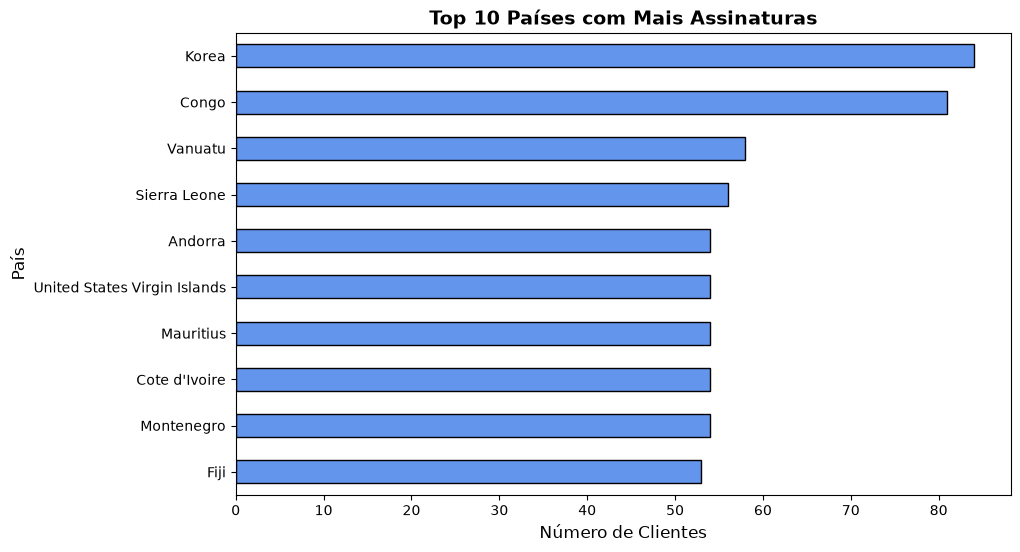

In [19]:
top_10_countries = df['Country'].value_counts().head(10)

plt.figure(figsize=(10, 6))

top_10_countries.sort_values().plot(kind='barh', color='cornflowerblue', edgecolor='black')

plt.title('Top 10 Países com Mais Assinaturas', fontsize=14, fontweight='bold')
plt.xlabel('Número de Clientes', fontsize=12)
plt.ylabel('País', fontsize=12)

plt.show()

Datas de Maior Venda:

In [20]:
df['Subscription Date'] = pd.to_datetime(df['Subscription Date'], errors='coerce')
vendas_por_ano = df['Subscription Date'].dt.year.value_counts()
print("Vendas por Ano:")
print(vendas_por_ano)

vendas_por_mes = df['Subscription Date'].dt.month.value_counts().sort_index()
print("\nVendas por Mês:")
print(vendas_por_mes)

Vendas por Ano:
Subscription Date
2020    4212
2021    4125
2022    1663
Name: count, dtype: int64

Vendas por Mês:
Subscription Date
1     1060
2      931
3     1076
4      989
5      978
6      666
7      691
8      766
9      656
10     717
11     723
12     747
Name: count, dtype: int64


In [38]:
df['Ano'] = df['Subscription Date'].dt.year
df['Mes'] = df['Subscription Date'].dt.month

vendas_por_ano_mes = df.groupby(['Ano', 'Mes']).size().reset_index(name='Total_Vendas')
print(vendas_por_ano_mes)

melhor_mes_por_ano = vendas_por_ano_mes.loc[vendas_por_ano_mes.groupby('Ano')['Total_Vendas'].idxmax()]

print("O melhor mês de cada ano:")
print(melhor_mes_por_ano)

     Ano  Mes  Total_Vendas
0   2020    1           338
1   2020    2           325
2   2020    3           351
3   2020    4           352
4   2020    5           347
5   2020    6           331
6   2020    7           358
7   2020    8           383
8   2020    9           322
9   2020   10           362
10  2020   11           373
11  2020   12           370
12  2021    1           367
13  2021    2           284
14  2021    3           384
15  2021    4           306
16  2021    5           317
17  2021    6           335
18  2021    7           333
19  2021    8           383
20  2021    9           334
21  2021   10           355
22  2021   11           350
23  2021   12           377
24  2022    1           355
25  2022    2           322
26  2022    3           341
27  2022    4           331
28  2022    5           314
O melhor mês de cada ano:
     Ano  Mes  Total_Vendas
7   2020    8           383
14  2021    3           384
24  2022    1           355


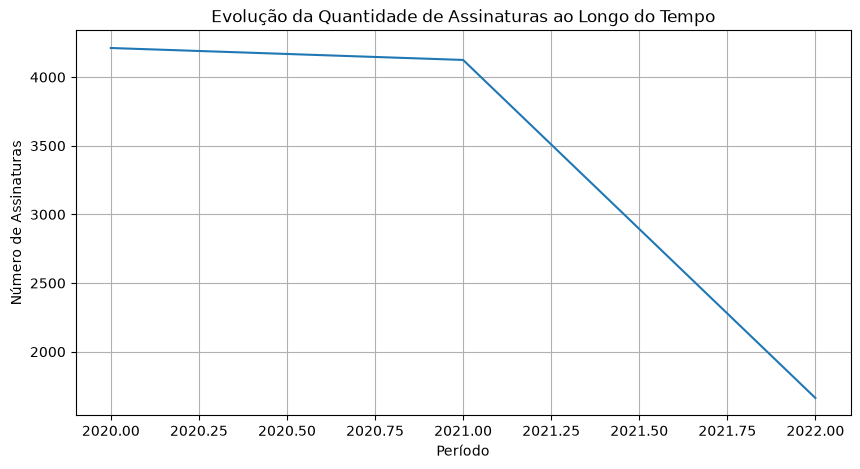

In [36]:
df['Subscription Date'] = pd.to_datetime(df['Subscription Date'], errors='coerce')

vendas_por_ano = df['Subscription Date'].dt.year.value_counts().sort_index()

plt.figure(figsize=(10, 5))

vendas_por_ano.plot()

plt.title('Evolução da Quantidade de Assinaturas ao Longo do Tempo')
plt.xlabel('Período')
plt.ylabel('Número de Assinaturas')
plt.grid(True)

plt.show()

O Maior Cliente (B2B):

Top 5 Maiores Empresas:
Empresa_Principal
Mack       24
Cortez     24
Heath      22
Pearson    20
Cochran    19
Name: count, dtype: int64


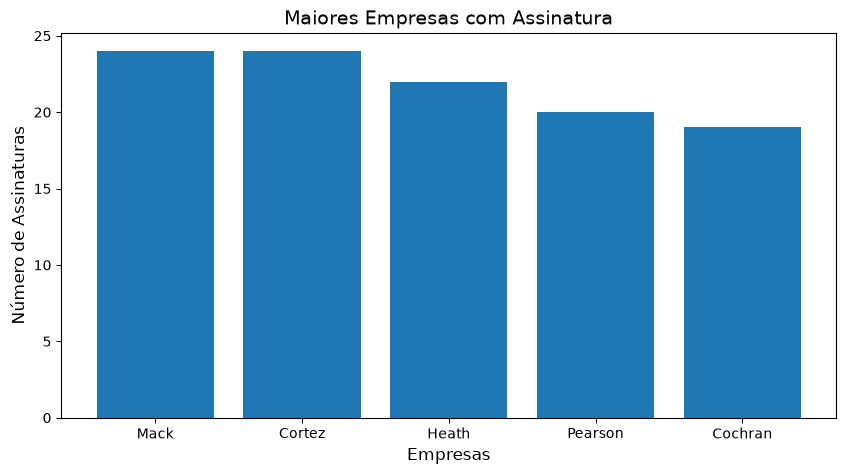

In [30]:
# Criar uma nova coluna pegando apenas a primeira palavra da empresa (ex: 'Google Inc' vira 'Google')
df["Empresa_Principal"] = (
    df["Company"]
    .str.extract(r"^([A-Za-z]+)", expand=False)
    .str.title()
)

# Contar as 5 maiores empresas
maiores_empresas = df["Empresa_Principal"].value_counts().head(5)
print("Top 5 Maiores Empresas:")
print(maiores_empresas)

# Criar o gráfico de colunas verticais
plt.figure(figsize=(10, 5))
plt.bar(
    maiores_empresas.index,
    maiores_empresas
)

# Títulos e rótulos
plt.title('Maiores Empresas com Assinatura', fontsize=14)
plt.xlabel('Empresas', fontsize=12)
plt.ylabel('Número de Assinaturas', fontsize=12)

plt.show()